In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers


In [2]:
# On Colab: Runtime -> Change runtime type -> T4 GPU
print(tf.config.list_physical_devices("GPU"))

[]


In [3]:
timesteps = 1000
embedding_dim = 128

In [ ]:
import os
import numpy as np
import tensorflow as tf

# Cache the (airplane-only) dataset on Google Drive so a Colab session
# reset doesn't force a re-download from the internet.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CACHE_PATH = "/content/drive/MyDrive/diffusion_cache/cifar10_airplanes.npz"
except ImportError:
    # Not running on Colab (e.g. local machine) - cache next to the notebook.
    CACHE_PATH = "cifar10_airplanes.npz"

os.makedirs(os.path.dirname(CACHE_PATH) or ".", exist_ok=True)

if os.path.exists(CACHE_PATH):
    print(f"Loading cached airplane-only CIFAR-10 from {CACHE_PATH}")
    cached = np.load(CACHE_PATH)
    x_train, y_train = cached["x_train"], cached["y_train"]
    x_test, y_test = cached["x_test"], cached["y_test"]
else:
    print("No cache found, downloading full CIFAR-10 (one-time cost)...")
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

    # Keep only one class: airplane (label 0)
    mask_train = y_train.flatten() == 0
    x_train = x_train[mask_train]
    y_train = y_train[mask_train]

    mask_test = y_test.flatten() == 0
    x_test = x_test[mask_test]
    y_test = y_test[mask_test]

    np.savez(CACHE_PATH, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test)
    print(f"Cached airplane-only CIFAR-10 to {CACHE_PATH}")

print(f"Shape of x_train (airplanes only): {x_train.shape}")
print(f"Min pixel value: {x_train.min()}, Max pixel value: {x_train.max()}")

In [ ]:
mask = y_train.flatten() == 0
x_train = x_train[mask]
y_train = y_train[mask]

# Normalize pixel values to [-1, 1]
# The reverse process starts from N(0, 1), so the data has to be
# centred on 0 for the forward process to actually end at pure noise.
# Guarded so re-running this cell (e.g. via "Run all" after it already
# ran once) doesn't normalize an already-normalized array.
if x_train.dtype != np.float32 or x_train.max() > 1.5:
    x_train = x_train.astype("float32") / 255.0
    x_train = x_train * 2.0 - 1.0


In [6]:
assert x_train.min() < -0.9 and x_train.max() > 0.9, \
    f"data range looks wrong: [{x_train.min():.3f}, {x_train.max():.3f}]"

In [7]:
print(x_train.shape)
print(y_train.shape)
# Display an image


(5000, 32, 32, 3)
(5000, 1)


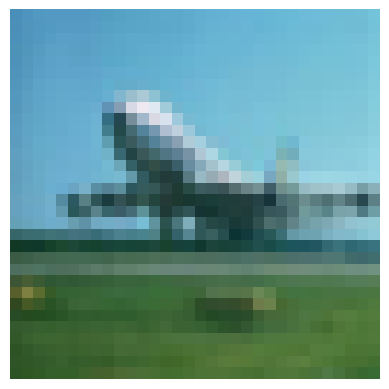

In [8]:
def to_display(x):
    """Map an image from [-1, 1] back to [0, 1] for plotting."""
    return np.clip((x + 1.0) / 2.0, 0.0, 1.0)


plt.imshow(to_display(x_train[100]))
plt.axis("off")
plt.show()

In [9]:
def forward_diffusion(x_0, t, beta_schedule):
    alpha = 1 - beta_schedule
    alpha_bar = np.cumprod(alpha)
    noise = np.random.normal(loc = 0, scale = 1,size=x_0.shape)
    x_t = np.sqrt(alpha_bar[t]) * x_0 +np.sqrt(1 - alpha_bar[t]) * noise
    return x_t, noise

In [10]:
def linear_schedule(timesteps, beta_start = 0.0001, beta_end = 0.02):
    return np.linspace(beta_start, beta_end, timesteps)

In [11]:
def cosine_schedule(timesteps, s=0.008):
    """Nichol & Dhariwal cosine schedule.

    The linear schedule destroys most of the signal in the first ~200 steps
    at 32x32, so a lot of the model's capacity is spent on timesteps that
    carry no information. The cosine schedule spreads the damage evenly.
    """
    steps = np.arange(timesteps + 1)
    f = np.cos(((steps / timesteps) + s) / (1 + s) * (np.pi / 2)) ** 2
    alpha_bar = f / f[0]
    betas = 1 - (alpha_bar[1:] / alpha_bar[:-1])
    return np.clip(betas, 0.0001, 0.999)

In [12]:
def visualise_timesteps(x_0, timesteps, beta_schedule):
    t = np.random.randint(0, timesteps, size = 5)
    t = np.append(t, [0, 5, 10, 50, 100])
    t.sort()
    fig, axes = plt.subplots(1, len(t), figsize=(15, 5))
    for i, timestep in enumerate(t):
        x_t, _ = forward_diffusion(x_0, timestep, beta_schedule)
        axes[i].imshow(to_display(x_t))
        axes[i].set_title(f'Timestep: {timestep}')
        axes[i].axis('off')
    plt.show()

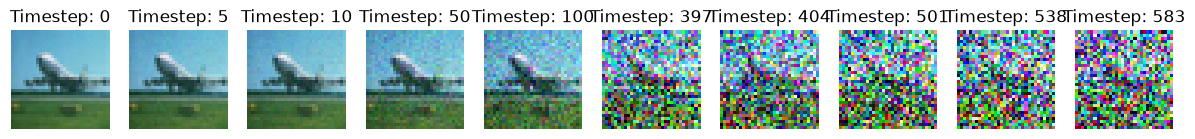

In [13]:
beta_schedule = cosine_schedule(timesteps)
x_0 = x_train[100]
visualise_timesteps(x_0, timesteps, beta_schedule)

# read these one code block again

In [14]:
def timestep_positional_encoding(timesteps, embedding_dim):
    pe = np.zeros((timesteps, embedding_dim))
    position = np.arange(0, timesteps, 1)
    power = np.arange(0, embedding_dim, 2) / embedding_dim
    pe[:, 0::2] = np.sin(position[:, np.newaxis] / (10000 ** power))
    pe[:, 1::2] = np.cos(position[:, np.newaxis] / (10000 ** power))
    return pe

In [15]:
pe = timestep_positional_encoding(timesteps, embedding_dim)
print(pe.shape)

(1000, 128)


In [16]:
print(pe[4])

[-7.56802495e-01 -6.53643621e-01 -3.16715428e-01 -9.48520605e-01
  1.41538923e-01 -9.89932691e-01  5.17619285e-01 -8.55611054e-01
  7.78471741e-01 -6.27679654e-01  9.29746055e-01 -3.68201403e-01
  9.93280735e-01 -1.15729782e-01  9.93945135e-01  1.09877515e-01
  9.53580740e-01  3.01137463e-01  8.89096683e-01  4.57719443e-01
  8.12570908e-01  5.82862351e-01  7.32107042e-01  6.81189606e-01
  6.52828002e-01  7.57506172e-01  5.77751019e-01  8.16213060e-01
  5.08471340e-01  8.61078914e-01  4.45661257e-01  8.95201678e-01
  3.89418342e-01  9.21060994e-01  3.39500428e-01  9.40605900e-01
  2.95479780e-01  9.55348994e-01  2.56841510e-01  9.66453537e-01
  2.23044492e-01  9.74808266e-01  1.93557577e-01  9.81088918e-01
  1.67879851e-01  9.85807464e-01  1.45550773e-01  9.89350783e-01
  1.26154067e-01  9.92010661e-01  1.09317874e-01  9.94006842e-01
  9.47127699e-02  9.95504641e-01  8.20486627e-02  9.96628324e-01
  7.10712085e-02  9.97471244e-01  6.15581165e-02  9.98103501e-01
  5.33155662e-02  9.98577

In [17]:
class ResBlock(layers.Layer):

    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = layers.Conv2D(
            out_channels, 3, padding="same"
        )
        # GroupNorm, not BatchNorm: every image in the batch carries a
        # different noise level, so batch statistics are meaningless here.
        self.norm1 = layers.GroupNormalization(groups=8)

        self.conv2 = layers.Conv2D(
            out_channels, 3, padding="same"
        )
        self.norm2 = layers.GroupNormalization(groups=8)

        self.time_proj = layers.Dense(out_channels)

        self.activation = layers.Activation("swish")

        if in_channels != out_channels:
            self.skip = layers.Conv2D(
                out_channels, 1, padding="same"
            )
        else:
            self.skip = None

    def call(self, x, t_emb):

        if self.skip is not None:
            residual = self.skip(x)
        else:
            residual = x

        h = self.conv1(x)
        h = self.norm1(h)

        time = self.time_proj(t_emb)
        time = time[:, tf.newaxis, tf.newaxis, :]

        h = h + time
        h = self.activation(h)

        h = self.conv2(h)
        h = self.norm2(h)

        h = h + residual
        h = self.activation(h)

        return h

In [18]:
class AttentionBlock(layers.Layer):
    """Self-attention over the 8x8 feature map.

    Convolutions only see a local window; one attention layer at the
    bottleneck lets every pixel look at every other pixel, which is what
    keeps a generated object globally coherent instead of locally plausible.
    """

    def __init__(self, channels, num_heads=4):
        super().__init__()

        self.norm = layers.GroupNormalization(groups=8)

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=channels // num_heads
        )

    def call(self, x):

        b = tf.shape(x)[0]
        h, w, c = x.shape[1], x.shape[2], x.shape[3]

        y = self.norm(x)
        y = tf.reshape(y, (b, h * w, c))
        y = self.attention(y, y)
        y = tf.reshape(y, (b, h, w, c))

        return x + y

In [19]:
class DownBlock(layers.Layer):

    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.resblock = ResBlock(
            in_channels,
            out_channels,
            time_dim
        )

        self.downsample = layers.Conv2D(
            out_channels,
            3,
            strides=2,
            padding="same"
        )

    def call(self, x, t_emb):

        x = self.resblock(x, t_emb)

        skip = x

        x = self.downsample(x)

        return x, skip

In [20]:
class UpBlock(layers.Layer):

    def __init__(self, in_channels, skip_channels, out_channels, time_dim):
        super().__init__()

        self.upsample = layers.Conv2DTranspose(
            out_channels,
            3,
            strides=2,
            padding="same"
        )

        self.resblock = ResBlock(
            out_channels + skip_channels,
            out_channels,
            time_dim
        )

    def call(self, x, skip, t_emb):

        x = self.upsample(x)

        x = tf.concat([x, skip], axis=-1)

        x = self.resblock(x, t_emb)

        return x

In [21]:
class UNet(tf.keras.Model):

    def __init__(self, input_shape, time_dim=128, base=64):
        super().__init__()

        self.time_dim = time_dim

        c1, c2, c3 = base, base * 2, base * 4

        # Let the network reshape the sinusoidal encoding itself
        self.time_mlp = tf.keras.Sequential([
            layers.Dense(time_dim * 2, activation="swish"),
            layers.Dense(time_dim * 2),
        ])

        # Input
        self.input_conv = layers.Conv2D(
            c1,
            3,
            padding="same"
        )

        # Downsampling
        self.down1 = DownBlock(
            c1, c2, time_dim
        )

        self.down2 = DownBlock(
            c2, c3, time_dim
        )

        # Bottleneck
        self.bottleneck1 = ResBlock(
            c3, c3, time_dim
        )

        self.attention = AttentionBlock(c3)

        self.bottleneck2 = ResBlock(
            c3, c3, time_dim
        )

        # Upsampling
        self.up2 = UpBlock(
            c3, c3, c2, time_dim
        )

        self.up1 = UpBlock(
            c2, c2, c1, time_dim
        )

        # Output
        self.output_conv = layers.Conv2D(
            3,
            3,
            padding="same"
        )

    def call(self, inputs):

        x, t_emb = inputs

        t_emb = self.time_mlp(t_emb)

        # Input
        x = self.input_conv(x)

        # Down
        x, skip1 = self.down1(x, t_emb)
        x, skip2 = self.down2(x, t_emb)

        # Bottleneck
        x = self.bottleneck1(x, t_emb)
        x = self.attention(x)
        x = self.bottleneck2(x, t_emb)

        # Up
        x = self.up2(x, skip2, t_emb)
        x = self.up1(x, skip1, t_emb)

        # Output
        x = self.output_conv(x)

        return x

## Next 2 blocks are just for testing no relevance

In [22]:
batch_size = 4

x_dummy = tf.random.normal(
    (batch_size, 32, 32, 3)
)

t_test = np.random.randint(
    0, timesteps, size=batch_size
)

t_emb_test = timestep_positional_encoding(
    timesteps,
    embedding_dim
)[t_test]

t_emb_test = tf.convert_to_tensor(
    t_emb_test,
    dtype=tf.float32
)

In [23]:
model = UNet(
    input_shape=(32, 32, 3),
    time_dim=embedding_dim,
    base=64
)

predicted_noise = model(
    [x_dummy, t_emb_test]
)

print("Input:", x_dummy.shape)
print("Time embedding:", t_emb_test.shape)
print("Output:", predicted_noise.shape)
print("Parameters:", f"{model.count_params():,}")

Input: (4, 32, 32, 3)
Time embedding: (4, 128)
Output: (4, 32, 32, 3)
Parameters: 6,064,131


In [24]:
mse = tf.keras.losses.MeanSquaredError()

def loss_fn(y_true, y_pred):
    return mse(y_true, y_pred)

In [25]:
def get_noisy_image(x_0, beta_schedule):

    batch_size = x_0.shape[0]

    x_0 = tf.cast(x_0, tf.float32)
    beta_schedule = tf.cast(beta_schedule, tf.float32)

    t = tf.random.uniform(
        shape=(batch_size,),
        minval=0,
        maxval=len(beta_schedule),
        dtype=tf.int32
    )

    alpha = 1 - beta_schedule
    alpha_bar = tf.math.cumprod(alpha)

    noise = tf.random.normal(
        shape=tf.shape(x_0),
        mean=0.0,
        stddev=1.0
    )

    alpha_bar_t = tf.gather(alpha_bar, t)
    alpha_bar_t = alpha_bar_t[:, tf.newaxis, tf.newaxis, tf.newaxis]

    x_t = (
        tf.sqrt(alpha_bar_t) * x_0
        + tf.sqrt(1 - alpha_bar_t) * noise
    )

    return x_t, noise, t

In [26]:
def get_gradients(model, x_0, beta_schedule):

    x_t, noise, t = get_noisy_image(
        x_0,
        beta_schedule
    )

    t_emb = timestep_positional_encoding(
        len(beta_schedule),
        model.time_dim
    )[t]

    t_emb = tf.convert_to_tensor(
        t_emb,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        predicted_noise = model(
            [x_t, t_emb],
            training=True
        )

        loss = loss_fn(
            noise,
            predicted_noise
        )

    gradients = tape.gradient(
        loss,
        model.trainable_variables
    )

    return loss, gradients

In [27]:
loss, gradients = get_gradients(
    model,
    x_train[:4],
    beta_schedule
)

print("Loss:", loss.numpy())

for i, grad in enumerate(gradients):
    print(i, grad.shape)

Loss: 2.1441512
0 (128, 256)
1 (256,)
2 (256, 256)
3 (256,)
4 (3, 3, 3, 64)
5 (64,)
6 (3, 3, 64, 128)
7 (128,)
8 (128,)
9 (128,)
10 (3, 3, 128, 128)
11 (128,)
12 (128,)
13 (128,)
14 (256, 128)
15 (128,)
16 (1, 1, 64, 128)
17 (128,)
18 (3, 3, 128, 128)
19 (128,)
20 (3, 3, 128, 256)
21 (256,)
22 (256,)
23 (256,)
24 (3, 3, 256, 256)
25 (256,)
26 (256,)
27 (256,)
28 (256, 256)
29 (256,)
30 (1, 1, 128, 256)
31 (256,)
32 (3, 3, 256, 256)
33 (256,)
34 (3, 3, 256, 256)
35 (256,)
36 (256,)
37 (256,)
38 (3, 3, 256, 256)
39 (256,)
40 (256,)
41 (256,)
42 (256, 256)
43 (256,)
44 (256,)
45 (256,)
46 (256, 4, 64)
47 (4, 64)
48 (256, 4, 64)
49 (4, 64)
50 (256, 4, 64)
51 (4, 64)
52 (4, 64, 256)
53 (256,)
54 (3, 3, 256, 256)
55 (256,)
56 (256,)
57 (256,)
58 (3, 3, 256, 256)
59 (256,)
60 (256,)
61 (256,)
62 (256, 256)
63 (256,)
64 (3, 3, 128, 256)
65 (128,)
66 (3, 3, 384, 128)
67 (128,)
68 (128,)
69 (128,)
70 (3, 3, 128, 128)
71 (128,)
72 (128,)
73 (128,)
74 (256, 128)
75 (128,)
76 (1, 1, 384, 128)
77 (1

In [28]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=2e-4
)

# Exponential moving average of the weights.
# Sampling from the EMA copy instead of the live weights is the single
# biggest visual-quality win in diffusion training.
# Re-run this cell if you ever rebuild `model`.
ema_decay = 0.999

ema_weights = [
    tf.Variable(v, trainable=False)
    for v in model.trainable_variables
]

ema_step = tf.Variable(0.0, trainable=False)


def swap_in_ema():
    """Move EMA weights into the model, returning the live weights."""
    backup = [tf.identity(v) for v in model.trainable_variables]
    for v, e in zip(model.trainable_variables, ema_weights):
        v.assign(e)
    return backup


def restore_weights(backup):
    for v, b in zip(model.trainable_variables, backup):
        v.assign(b)

In [ ]:
# Checkpoint to Drive periodically so a dropped/expired Colab session
# (or a git pull that reruns cells) only costs a few epochs, not the
# whole run. Re-running this cell auto-resumes from the latest checkpoint.
CKPT_DIR = os.path.join(os.path.dirname(CACHE_PATH), "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

checkpoint = tf.train.Checkpoint(
    model=model,
    optimizer=optimizer,
    ema_weights=ema_weights,
    ema_step=ema_step,
    epoch=tf.Variable(0, dtype=tf.int64, trainable=False),
)
ckpt_manager = tf.train.CheckpointManager(checkpoint, CKPT_DIR, max_to_keep=3)

start_epoch = 0
history = []
history_path = os.path.join(CKPT_DIR, "history.npy")

if ckpt_manager.latest_checkpoint:
    checkpoint.restore(ckpt_manager.latest_checkpoint).expect_partial()
    start_epoch = int(checkpoint.epoch.numpy())
    if os.path.exists(history_path):
        history = list(np.load(history_path))
    print(f"Resumed from checkpoint: epoch {start_epoch}, {len(history)} loss values loaded")
else:
    print("No checkpoint found, starting fresh.")


def save_checkpoint(epoch):
    checkpoint.epoch.assign(epoch)
    ckpt_manager.save()
    np.save(history_path, np.array(history))

In [29]:
PE = tf.constant(
    timestep_positional_encoding(timesteps, embedding_dim),
    dtype=tf.float32
)

BETA = tf.constant(beta_schedule, dtype=tf.float32)
ALPHA = 1.0 - BETA
ALPHA_BAR = tf.math.cumprod(ALPHA)
ALPHA_BAR_PREV = tf.concat([[1.0], ALPHA_BAR[:-1]], axis=0)


@tf.function
def train_step(x_0):

    batch = tf.shape(x_0)[0]

    t = tf.random.uniform(
        (batch,), 0, timesteps, dtype=tf.int32
    )

    noise = tf.random.normal(tf.shape(x_0))

    alpha_bar_t = tf.gather(ALPHA_BAR, t)[:, None, None, None]

    x_t = (
        tf.sqrt(alpha_bar_t) * x_0
        + tf.sqrt(1.0 - alpha_bar_t) * noise
    )

    t_emb = tf.gather(PE, t)

    with tf.GradientTape() as tape:

        predicted_noise = model([x_t, t_emb], training=True)

        loss = loss_fn(noise, predicted_noise)

    gradients = tape.gradient(loss, model.trainable_variables)

    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    # EMA update, with a warm-up so the average is usable early on
    ema_step.assign_add(1.0)
    d = tf.minimum(ema_decay, (1.0 + ema_step) / (10.0 + ema_step))
    for e, v in zip(ema_weights, model.trainable_variables):
        e.assign(d * e + (1.0 - d) * v)

    return loss

## Sampling

Defined before training so the training loop can preview samples as it goes.

In [30]:
def show_images(images, title=None, cols=8):
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5))
    flat = np.array(axes).reshape(-1)
    for ax, img in zip(flat, images):
        ax.imshow(img)
        ax.axis("off")
    for ax in flat[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def show_trajectory(trajectory):
    n_images = trajectory[0][1].shape[0]
    n_steps = len(trajectory)
    fig, axes = plt.subplots(n_images, n_steps,
                             figsize=(n_steps * 1.4, n_images * 1.4))
    axes = np.array(axes).reshape(n_images, n_steps)
    for col, (t, imgs) in enumerate(trajectory):
        for row in range(n_images):
            axes[row, col].imshow(imgs[row])
            axes[row, col].axis("off")
        axes[0, col].set_title(f"t={t}", fontsize=8)
    plt.tight_layout()
    plt.show()

In [31]:
@tf.function
def predict(x, t_emb):
    return model([x, t_emb], training=False)


def ddim_sample(n_images=8, image_shape=(32, 32, 3), n_steps=100, eta=0.0):

    step_indices = np.linspace(0, timesteps - 1, n_steps).round().astype(int)[::-1]

    x_t = tf.random.normal((n_images,) + image_shape)

    for i, t in enumerate(step_indices):

        t_prev = step_indices[i + 1] if i + 1 < len(step_indices) else -1

        alpha_bar_t = ALPHA_BAR[t]
        alpha_bar_prev = ALPHA_BAR[t_prev] if t_prev >= 0 else tf.constant(1.0)

        t_emb = tf.tile(PE[t][tf.newaxis, :], [n_images, 1])

        predicted_noise = predict(x_t, t_emb)

        x_0_pred = (
            x_t - tf.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / tf.sqrt(alpha_bar_t)
        x_0_pred = tf.clip_by_value(x_0_pred, -1.0, 1.0)

        sigma = eta * tf.sqrt(
            (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t)
            * (1.0 - alpha_bar_t / alpha_bar_prev)
        )

        direction = tf.sqrt(
            tf.maximum(1.0 - alpha_bar_prev - sigma ** 2, 0.0)
        ) * predicted_noise

        x_t = tf.sqrt(alpha_bar_prev) * x_0_pred + direction

        if eta > 0 and t_prev >= 0:
            x_t += sigma * tf.random.normal(tf.shape(x_t))

    return to_display(x_t.numpy())

In [ ]:
def ddpm_sample(model, n_images=8, image_shape=(32, 32, 3),
                return_trajectory=False, snapshot_every=100):

    x_t = tf.random.normal((n_images,) + image_shape)

    trajectory = []

    for t in reversed(range(timesteps)):

        t_emb = tf.tile(PE[t][tf.newaxis, :], [n_images, 1])

        predicted_noise = predict(x_t, t_emb)

        # Clip the predicted x0 every step (matches ddim_sample) so a bad
        # noise prediction can't compound unbounded over 1000 sequential
        # steps.
        x0_pred = (
            x_t - tf.sqrt(1.0 - ALPHA_BAR[t]) * predicted_noise
        ) / tf.sqrt(ALPHA_BAR[t])
        x0_pred = tf.clip_by_value(x0_pred, -1.0, 1.0)

        mean = (
            tf.sqrt(ALPHA_BAR_PREV[t]) * BETA[t] / (1.0 - ALPHA_BAR[t]) * x0_pred
            + tf.sqrt(ALPHA[t]) * (1.0 - ALPHA_BAR_PREV[t]) / (1.0 - ALPHA_BAR[t]) * x_t
        )

        if t > 0:
            variance = (
                BETA[t] * (1.0 - ALPHA_BAR_PREV[t]) / (1.0 - ALPHA_BAR[t])
            )
            x_t = mean + tf.sqrt(variance) * tf.random.normal(tf.shape(x_t))
        else:
            x_t = mean

        if return_trajectory and (t % snapshot_every == 0 or t == timesteps - 1):
            trajectory.append((t, to_display(x_t.numpy())))

    images = to_display(x_t.numpy())

    if return_trajectory:
        return images, trajectory

    return images

In [33]:
assert x_train.min() < -0.9 and x_train.max() > 0.9, \
    f"data range looks wrong: [{x_train.min():.3f}, {x_train.max():.3f}]"

## Train

On a Colab T4 expect roughly 5-10 s/epoch, so 400 epochs is about 30-60 minutes.
Loss should fall to around 0.03-0.04; below ~0.05 the samples start showing sky and fuselage shapes.
The preview every 100 epochs uses the EMA weights, so you can stop early if it already looks good.

In [ ]:
epochs = 100
batch_size = 128
checkpoint_every = 5  # epochs; keep this low so a dropped session loses little

dataset = (
    tf.data.Dataset
    .from_tensor_slices(x_train)
    .map(
        lambda im: tf.image.random_flip_left_right(im),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .shuffle(5000)
    .batch(batch_size, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

for epoch in range(start_epoch, epochs):

    losses = [float(train_step(x_batch)) for x_batch in dataset]
    history.append(np.mean(losses))

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1}, Loss: {history[-1]:.4f}")

    if (epoch + 1) % checkpoint_every == 0 or epoch == epochs - 1:
        save_checkpoint(epoch + 1)

    # Peek at samples while it trains
    if (epoch + 1) % 100 == 0:
        backup = swap_in_ema()
        show_images(
            ddim_sample(8, n_steps=100),
            title=f"epoch {epoch + 1}",
            cols=8
        )
        restore_weights(backup)

## Generate

In [ ]:
backup = swap_in_ema()

samples = ddpm_sample(model, n_images=16)

show_images(samples, title="Generated airplanes (DDPM, 1000 steps, EMA)")

restore_weights(backup)

In [ ]:
backup = swap_in_ema()

_, trajectory = ddpm_sample(
    model,
    n_images=3,
    return_trajectory=True,
    snapshot_every=100
)

show_trajectory(trajectory)

restore_weights(backup)

In [ ]:
backup = swap_in_ema()

samples_fast = ddim_sample(16, n_steps=100)

show_images(samples_fast, title="Generated airplanes (DDIM, 100 steps, EMA)")

restore_weights(backup)

In [ ]:
# Save both the live weights and the EMA copy
model.save_weights("diffusion_airplanes.weights.h5")

backup = swap_in_ema()
model.save_weights("diffusion_airplanes_ema.weights.h5")
restore_weights(backup)

# To reload later:
# model = UNet(input_shape=(32, 32, 3), time_dim=embedding_dim, base=64)
# model([tf.zeros((1, 32, 32, 3)), tf.zeros((1, embedding_dim))])   # build first
# model.load_weights("diffusion_airplanes_ema.weights.h5")

## Blur + Noise Diffusion (Cold Diffusion style)

A second, self-contained pipeline: the forward process blurs *and* adds
noise together at each timestep (instead of noise alone), and one model is
trained to reverse both jointly. It shares the dataset and the `ALPHA_BAR`
schedule from above, but has its own model, optimizer, checkpoint, training
loop, and sampler — nothing above this point is modified, so the Gaussian
pipeline stays intact for comparison.

Since the degradation isn't purely additive noise, the model is trained to
predict `x0` directly (Cold Diffusion's approach for compound degradations)
rather than predicting noise.

In [ ]:
SIGMA_MAX = 2.5
KERNEL_SIZE = 17


def gaussian_kernel_2d(sigma, size):
    ax = np.arange(-(size // 2), size // 2 + 1, dtype=np.float32)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * max(sigma, 1e-3) ** 2))
    kernel /= kernel.sum()
    return kernel


# Blur sigma ramps up on the same schedule as the noise (alpha_bar), so both
# forms of corruption reach full strength together at the last timestep.
blur_sigma = SIGMA_MAX * (1.0 - np.sqrt(ALPHA_BAR.numpy()))

BLUR_KERNELS = tf.constant(
    np.stack([gaussian_kernel_2d(s, KERNEL_SIZE) for s in blur_sigma]),
    dtype=tf.float32
)  # shape: (timesteps, KERNEL_SIZE, KERNEL_SIZE)

print("BLUR_KERNELS shape:", BLUR_KERNELS.shape)

In [ ]:
def apply_blur(x, t_indices):
    """Blur every image in the batch by its own per-example kernel (indexed
    by t), in a single depthwise convolution.

    The trick: fold the batch dimension into the channel dimension so each
    example gets its own filter, since tf.nn.depthwise_conv2d applies one
    filter per input channel.
    """
    b = tf.shape(x)[0]
    h, w, c = x.shape[1], x.shape[2], x.shape[3]

    kernels = tf.gather(BLUR_KERNELS, t_indices)                    # [B, K, K]
    kernels = tf.repeat(kernels[:, :, :, tf.newaxis], c, axis=-1)   # [B, K, K, C]
    kernels = tf.transpose(kernels, [1, 2, 0, 3])                   # [K, K, B, C]
    kernels = tf.reshape(kernels, [KERNEL_SIZE, KERNEL_SIZE, b * c, 1])

    x_r = tf.transpose(x, [1, 2, 0, 3])                             # [H, W, B, C]
    x_r = tf.reshape(x_r, [1, h, w, b * c])

    blurred = tf.nn.depthwise_conv2d(
        x_r, kernels, strides=[1, 1, 1, 1], padding="SAME"
    )                                                                # [1, H, W, B*C]

    blurred = tf.reshape(blurred, [h, w, b, c])
    blurred = tf.transpose(blurred, [2, 0, 1, 3])                   # [B, H, W, C]
    return blurred


def degrade_blur_noise(x0, t_indices, noise):
    """Combined corruption: blur x0 by the timestep's sigma, then blend with
    noise using the same alpha_bar weighting as the Gaussian pipeline."""
    alpha_bar_t = tf.gather(ALPHA_BAR, t_indices)[:, tf.newaxis, tf.newaxis, tf.newaxis]
    blurred = apply_blur(x0, t_indices)
    return tf.sqrt(alpha_bar_t) * blurred + tf.sqrt(1.0 - alpha_bar_t) * noise

In [ ]:
model_blur = UNet(
    input_shape=(32, 32, 3),
    time_dim=embedding_dim,
    base=64
)

# Build the model so its weights exist before EMA/checkpoint setup.
model_blur([tf.zeros((1, 32, 32, 3)), tf.zeros((1, embedding_dim))])

optimizer_blur = tf.keras.optimizers.Adam(learning_rate=2e-4)

ema_weights_blur = [
    tf.Variable(v, trainable=False)
    for v in model_blur.trainable_variables
]

ema_step_blur = tf.Variable(0.0, trainable=False)


def swap_in_ema_blur():
    backup = [tf.identity(v) for v in model_blur.trainable_variables]
    for v, e in zip(model_blur.trainable_variables, ema_weights_blur):
        v.assign(e)
    return backup


def restore_weights_blur(backup):
    for v, b in zip(model_blur.trainable_variables, backup):
        v.assign(b)

In [ ]:
# Checkpointing for the blur model, mirroring the Gaussian pipeline's setup
# (same Drive-backed auto-resume behavior).
CKPT_DIR_BLUR = os.path.join(os.path.dirname(CACHE_PATH), "checkpoints_blur")
os.makedirs(CKPT_DIR_BLUR, exist_ok=True)

checkpoint_blur = tf.train.Checkpoint(
    model=model_blur,
    optimizer=optimizer_blur,
    ema_weights=ema_weights_blur,
    ema_step=ema_step_blur,
    epoch=tf.Variable(0, dtype=tf.int64, trainable=False),
)
ckpt_manager_blur = tf.train.CheckpointManager(checkpoint_blur, CKPT_DIR_BLUR, max_to_keep=3)

start_epoch_blur = 0
history_blur = []
history_blur_path = os.path.join(CKPT_DIR_BLUR, "history.npy")

if ckpt_manager_blur.latest_checkpoint:
    checkpoint_blur.restore(ckpt_manager_blur.latest_checkpoint).expect_partial()
    start_epoch_blur = int(checkpoint_blur.epoch.numpy())
    if os.path.exists(history_blur_path):
        history_blur = list(np.load(history_blur_path))
    print(f"Resumed blur model from checkpoint: epoch {start_epoch_blur}, {len(history_blur)} loss values loaded")
else:
    print("No blur model checkpoint found, starting fresh.")


def save_checkpoint_blur(epoch):
    checkpoint_blur.epoch.assign(epoch)
    ckpt_manager_blur.save()
    np.save(history_blur_path, np.array(history_blur))

In [ ]:
@tf.function
def train_step_blur(x_0):

    batch = tf.shape(x_0)[0]

    t = tf.random.uniform(
        (batch,), 0, timesteps, dtype=tf.int32
    )

    noise = tf.random.normal(tf.shape(x_0))

    x_t = degrade_blur_noise(x_0, t, noise)

    t_emb = tf.gather(PE, t)

    with tf.GradientTape() as tape:

        x0_pred = model_blur([x_t, t_emb], training=True)

        # x0-prediction objective: the combined blur+noise degradation
        # isn't purely additive, so predicting "the noise" wouldn't invert
        # it the way it does in the Gaussian pipeline.
        loss = loss_fn(x_0, x0_pred)

    gradients = tape.gradient(loss, model_blur.trainable_variables)

    optimizer_blur.apply_gradients(
        zip(gradients, model_blur.trainable_variables)
    )

    ema_step_blur.assign_add(1.0)
    d = tf.minimum(ema_decay, (1.0 + ema_step_blur) / (10.0 + ema_step_blur))
    for e, v in zip(ema_weights_blur, model_blur.trainable_variables):
        e.assign(d * e + (1.0 - d) * v)

    return loss

In [ ]:
@tf.function
def predict_blur(x, t_emb):
    return model_blur([x, t_emb], training=False)


def cold_sample(n_images=8, image_shape=(32, 32, 3), n_steps=None):
    """Cold-Diffusion-style restart sampler for the combined blur+noise
    degradation. At every step it re-estimates (and clips) x0, then moves
    from x_t to x_{t-1} using the difference between the degradation
    applied at t and at t-1 - the same trick that keeps ddim_sample stable,
    generalized to a degradation that isn't pure noise. x_t is initialized
    to the SAME noise realization that degrade() reuses at every step, so
    the x_t - degrade(x0_hat, t) term cancels almost completely at the
    first step (t=999, where alpha_bar~0 and the degradation is ~pure
    noise) instead of injecting an unrelated Gaussian draw.
    """
    if n_steps is None:
        n_steps = timesteps

    step_indices = np.linspace(0, timesteps - 1, n_steps).round().astype(int)[::-1]

    fixed_noise = tf.random.normal((n_images,) + image_shape)
    x_t = fixed_noise

    for i, t in enumerate(step_indices):

        t_prev = step_indices[i + 1] if i + 1 < len(step_indices) else -1

        t_batch = tf.fill([n_images], t)
        t_emb = tf.tile(PE[t][tf.newaxis, :], [n_images, 1])

        x0_hat = predict_blur(x_t, t_emb)
        x0_hat = tf.clip_by_value(x0_hat, -1.0, 1.0)

        if t_prev >= 0:
            d_t = degrade_blur_noise(x0_hat, t_batch, fixed_noise)
            t_prev_batch = tf.fill([n_images], t_prev)
            d_prev = degrade_blur_noise(x0_hat, t_prev_batch, fixed_noise)
            x_t = x_t - d_t + d_prev
        else:
            x_t = x0_hat

    return to_display(x_t.numpy())

### Train the blur+noise model

Separate model from the Gaussian one above, so this needs its own full
training run - no shortcut from the existing weights. Uses the same
`dataset` defined earlier.

In [ ]:
epochs_blur = 100
checkpoint_every_blur = 5

for epoch in range(start_epoch_blur, epochs_blur):

    losses = [float(train_step_blur(x_batch)) for x_batch in dataset]
    history_blur.append(np.mean(losses))

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1}, Loss: {history_blur[-1]:.4f}")

    if (epoch + 1) % checkpoint_every_blur == 0 or epoch == epochs_blur - 1:
        save_checkpoint_blur(epoch + 1)

    if (epoch + 1) % 100 == 0:
        backup = swap_in_ema_blur()
        show_images(
            cold_sample(8, n_steps=100),
            title=f"blur+noise, epoch {epoch + 1}",
            cols=8
        )
        restore_weights_blur(backup)

### Compare: Gaussian DDIM vs blur+noise Cold Diffusion

In [ ]:
backup = swap_in_ema()
gaussian_samples = ddim_sample(8, n_steps=100)
restore_weights(backup)

backup_blur = swap_in_ema_blur()
blur_samples = cold_sample(8, n_steps=100)
restore_weights_blur(backup_blur)

show_images(gaussian_samples, title="Gaussian DDIM (100 steps, EMA)", cols=8)
show_images(blur_samples, title="Blur + Noise Cold Diffusion (100 steps, EMA)", cols=8)